# Guía práctica 4

## Ejercicio 1

In [1]:
from matplotlib.pyplot import show, subplots, tight_layout
from numpy import abs, angle, arange, log10, pi, sin
from numpy.fft import fft, fftfreq, fftshift
from scipy.signal import square

In [2]:
sampling_freq_hz = 1000
sampling_period_s = 1 / sampling_freq_hz
n_samples = 1024
freq_resolution_hz = sampling_freq_hz / n_samples

t = arange(n_samples) * sampling_period_s

In [ ]:
def plot_spectrum(x, sampling_freq_hz, name):
    n = x.size
    X = fft(x)
    magnitude = abs(X)
    phase = angle(X)

    # fftshift reorders the data, so the frequency axis has to be reordered too.
    k = arange(n)
    f = k * sampling_freq_hz / n
    f_centered = fftshift(fftfreq(n, 1 / sampling_freq_hz))

    rows = [
        ("bin FFT", k, magnitude, phase),
        ("Frecuencia [Hz]", f, magnitude, phase),
        (
            "Frecuencia [Hz] (centrada)",
            f_centered,
            fftshift(magnitude),
            fftshift(phase),
        ),
    ]

    fig, ax = subplots(3, 2, figsize=(11, 9), dpi=150)
    for i, (label, axis, mag, ph) in enumerate(rows):
        ax[i][0].plot(axis, 20 * log10(mag))
        ax[i][0].set_ylabel("Amplitud [dB]")
        ax[i][1].plot(axis, ph)
        ax[i][1].set_ylabel("Fase [rad]")
        for a in ax[i]:
            a.set_xlabel(label)
            a.set_xlim(axis[0], axis[-1])
            a.grid(True)

    ax[0][0].set_title(f"{name} - espectro de amplitud")
    ax[0][1].set_title(f"{name} - espectro de fase")
    tight_layout()
    show()

### a) Sinusoide de amplitud 5 y frecuencia 100 Hz

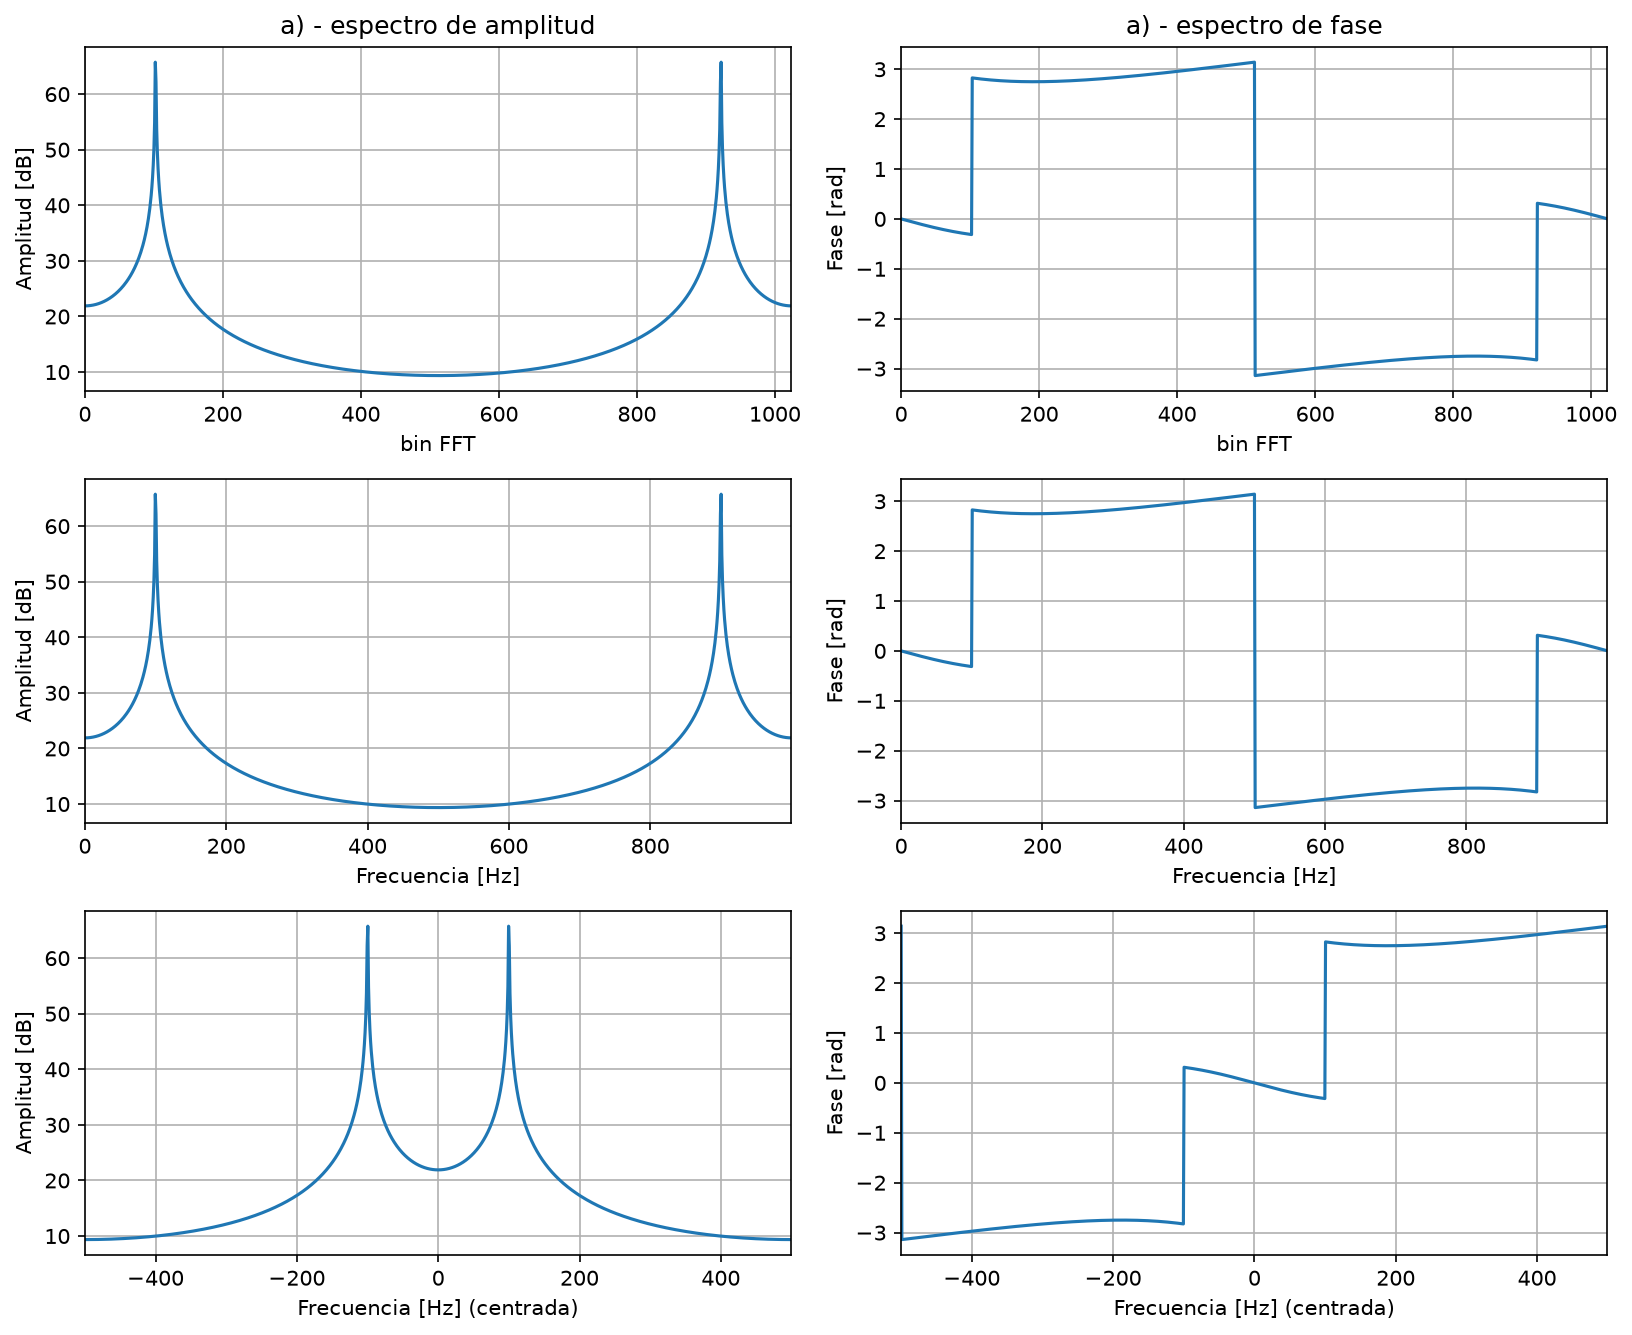

In [4]:
x_a = 5 * sin(2 * pi * 100 * t)

plot_spectrum(x_a, sampling_freq_hz, "a)")

### b) Sinusoide de amplitud 5 y frecuencia $20 f_s / N$

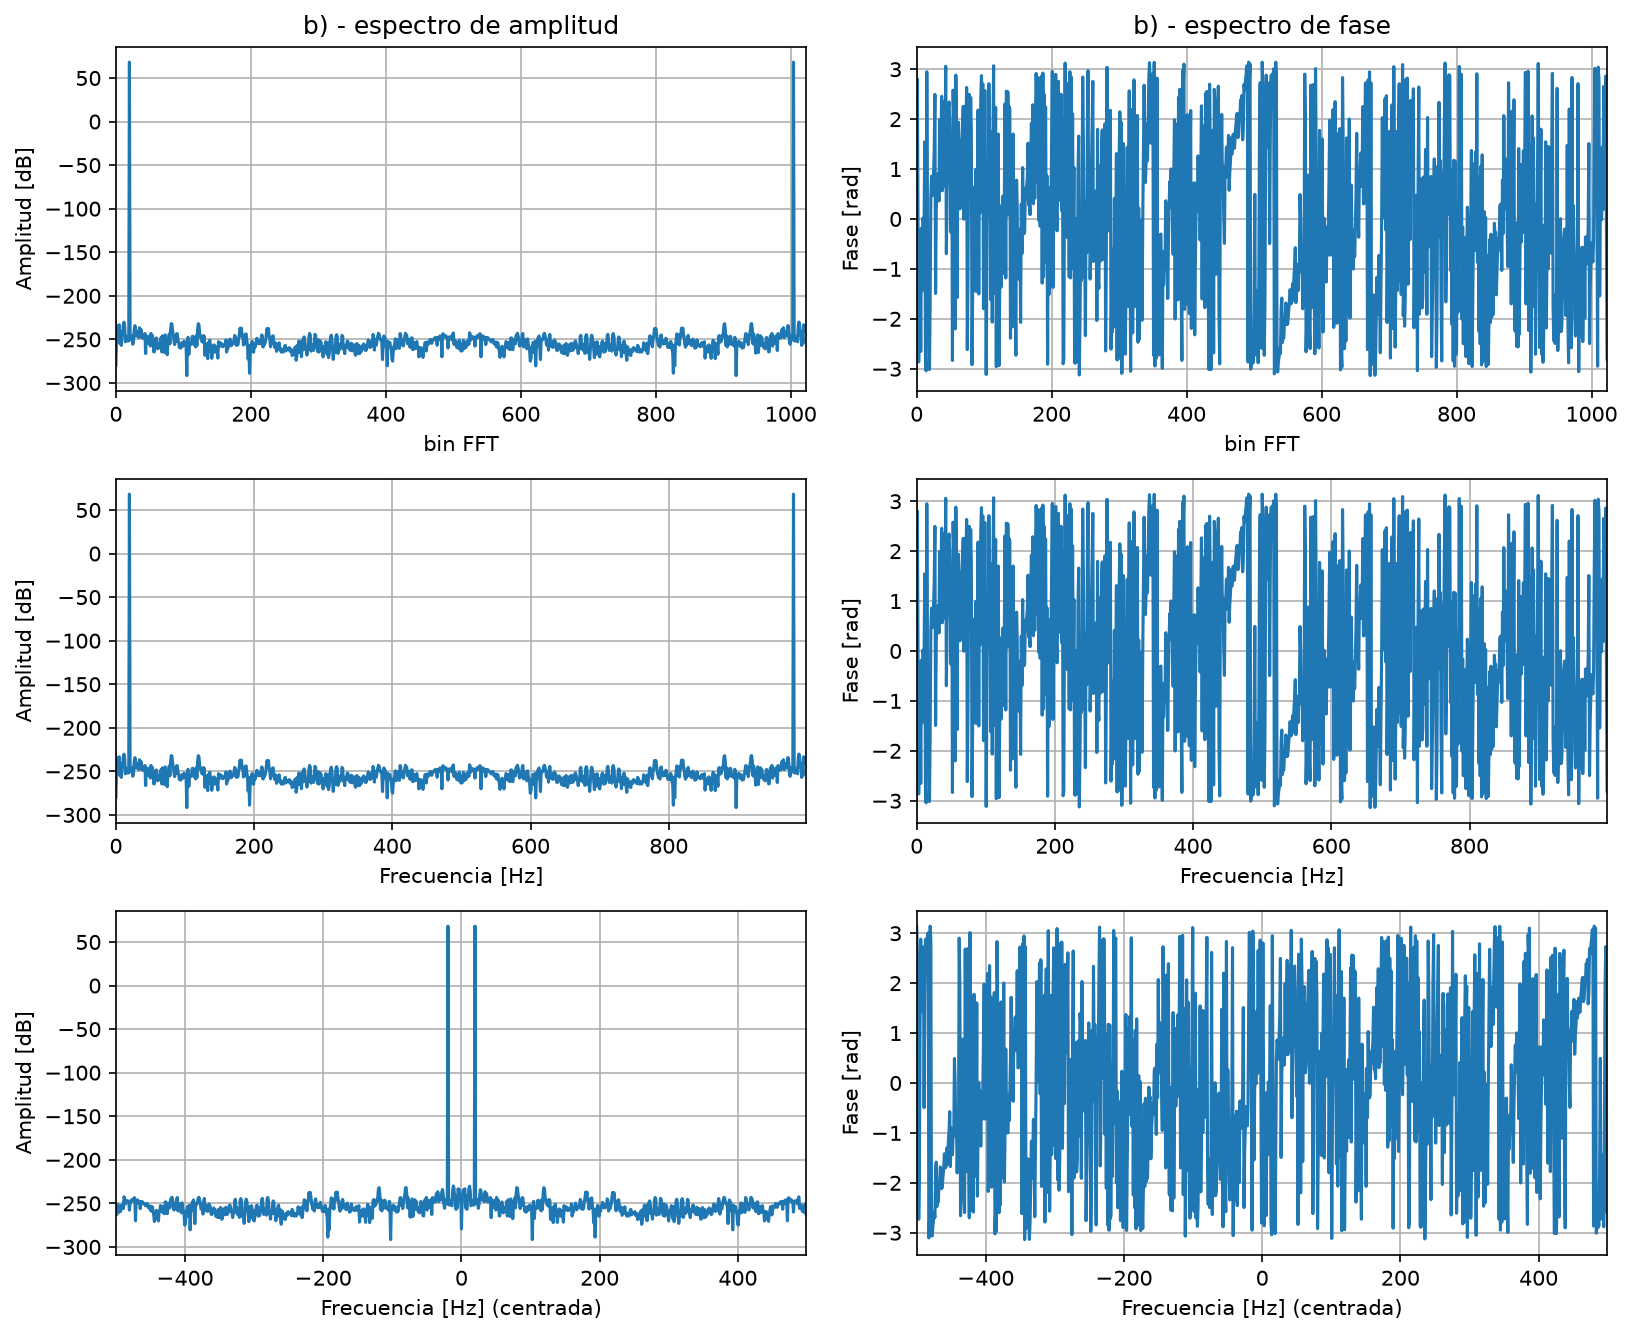

In [5]:
signal_freq_b_hz = 20 * freq_resolution_hz
x_b = 5 * sin(2 * pi * signal_freq_b_hz * t)

plot_spectrum(x_b, sampling_freq_hz, "b)")

### c) Suma de 100 Hz con amplitud 5 y 400 Hz con amplitud 1

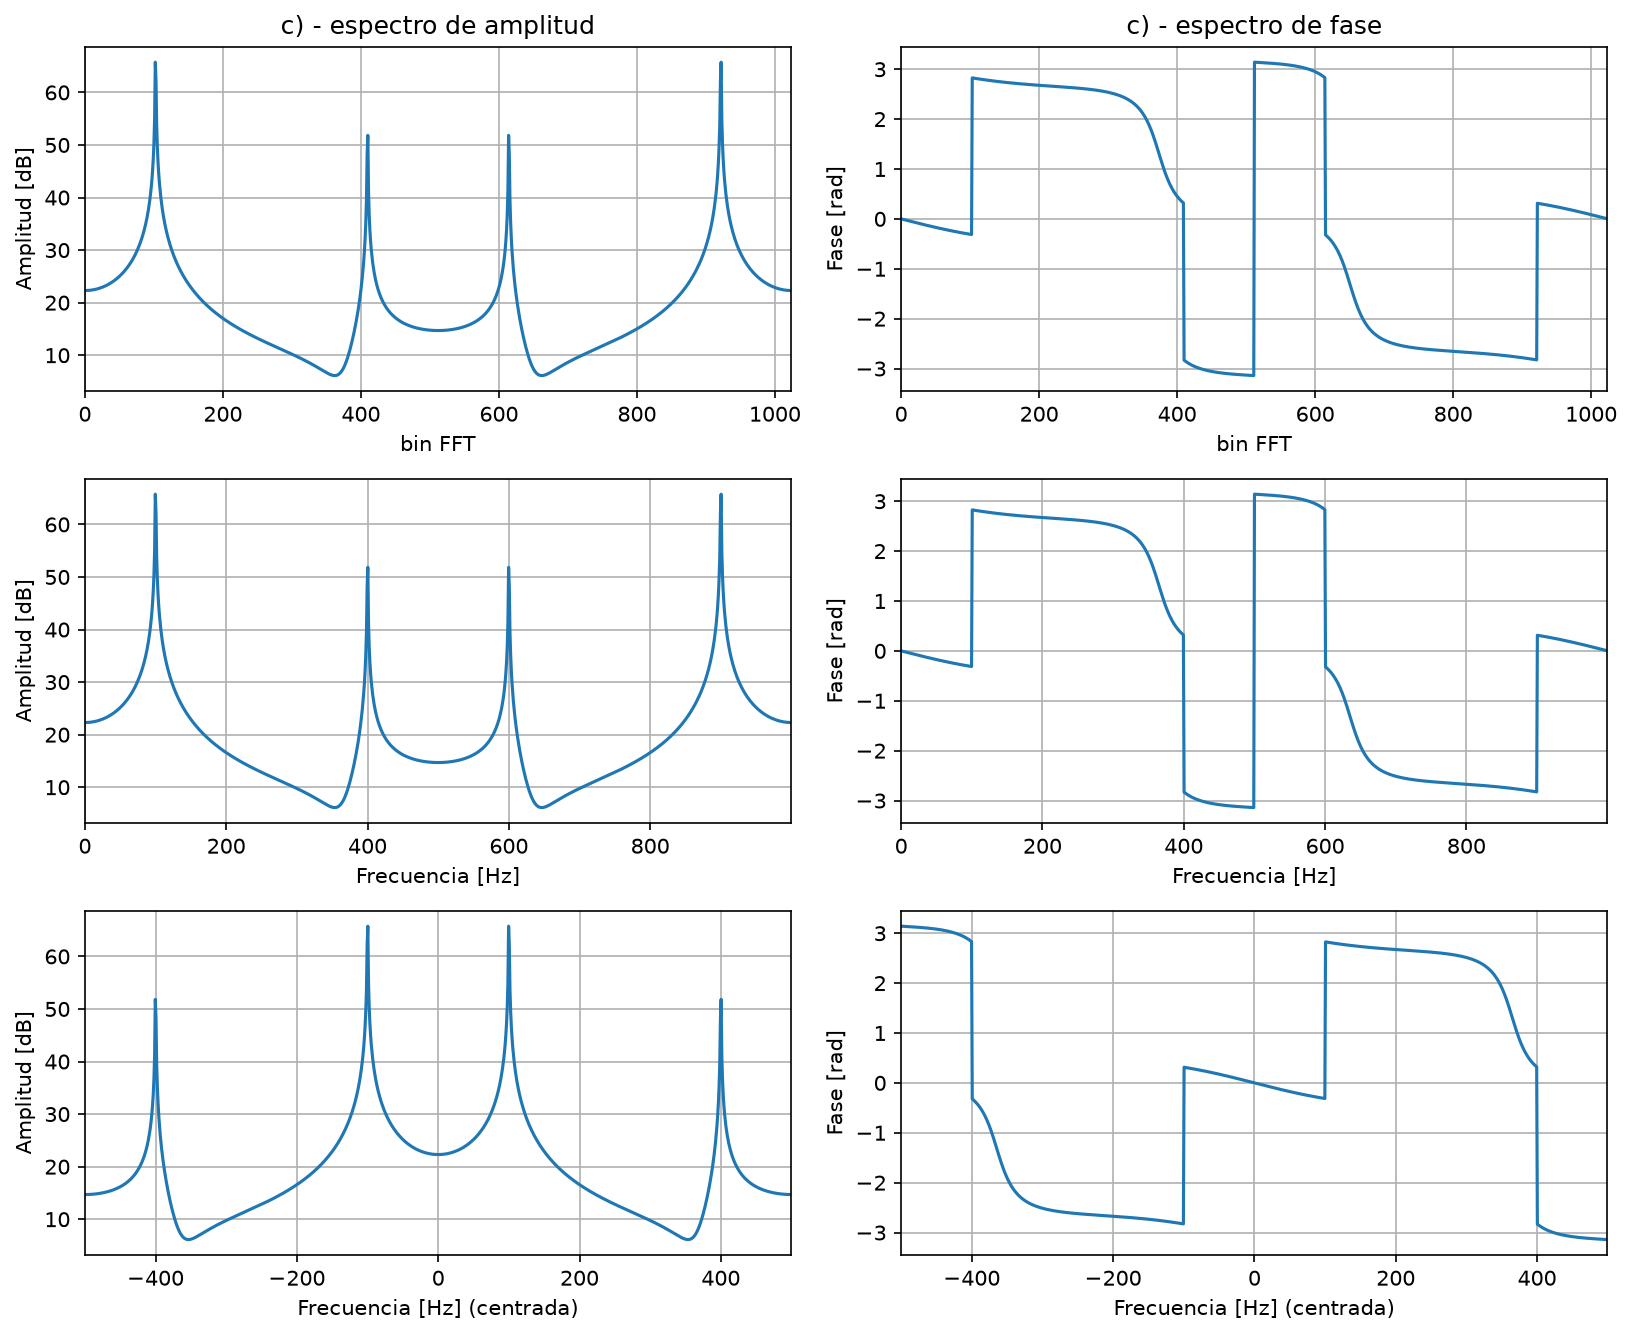

In [6]:
x_c = 5 * sin(2 * pi * 100 * t) + 1 * sin(2 * pi * 400 * t)

plot_spectrum(x_c, sampling_freq_hz, "c)")

### d) Onda cuadrada de 200 Hz y amplitud pico a pico 2

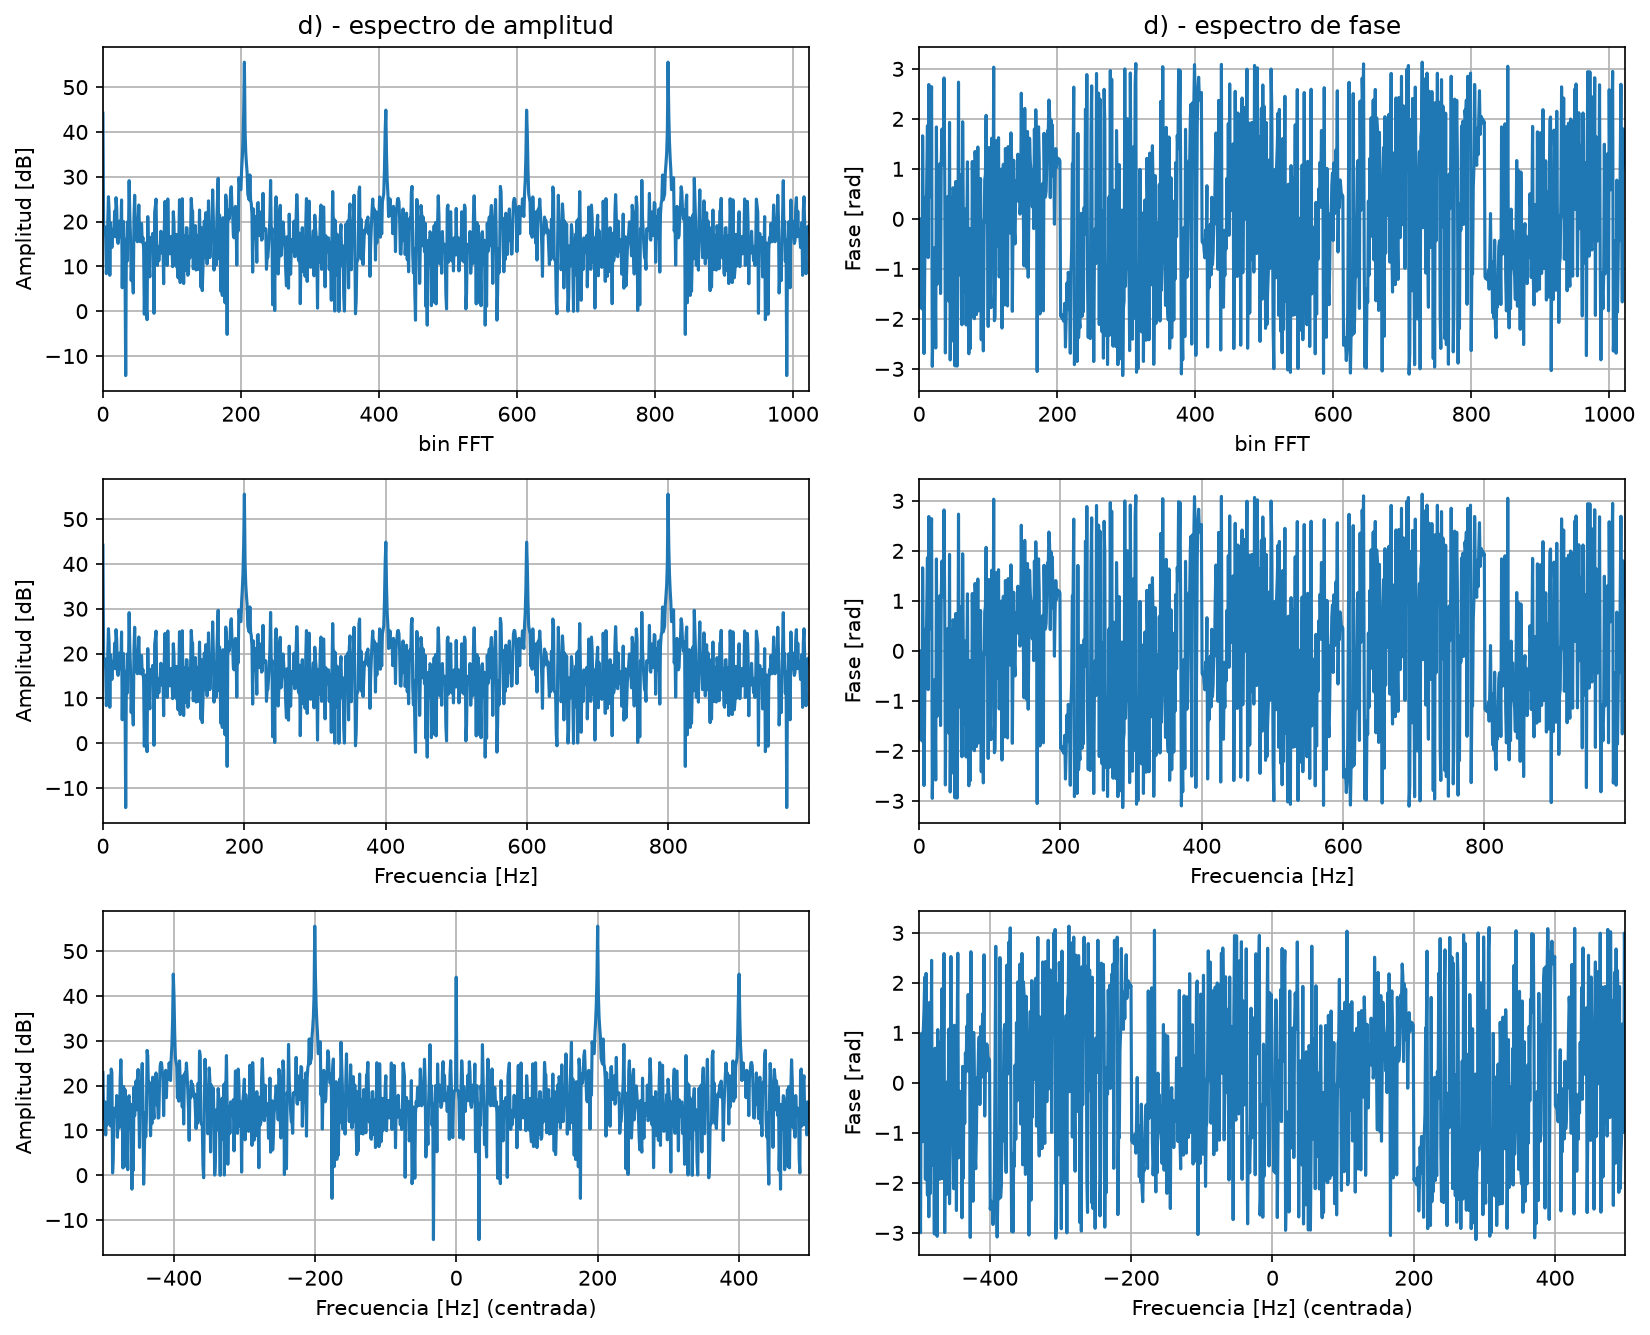

In [7]:
x_d = square(2 * pi * 200 * t)

plot_spectrum(x_d, sampling_freq_hz, "d)")

### e) Sinusoide de 100 Hz y amplitud 1 modulada en amplitud por una de 20 Hz y amplitud 0.5

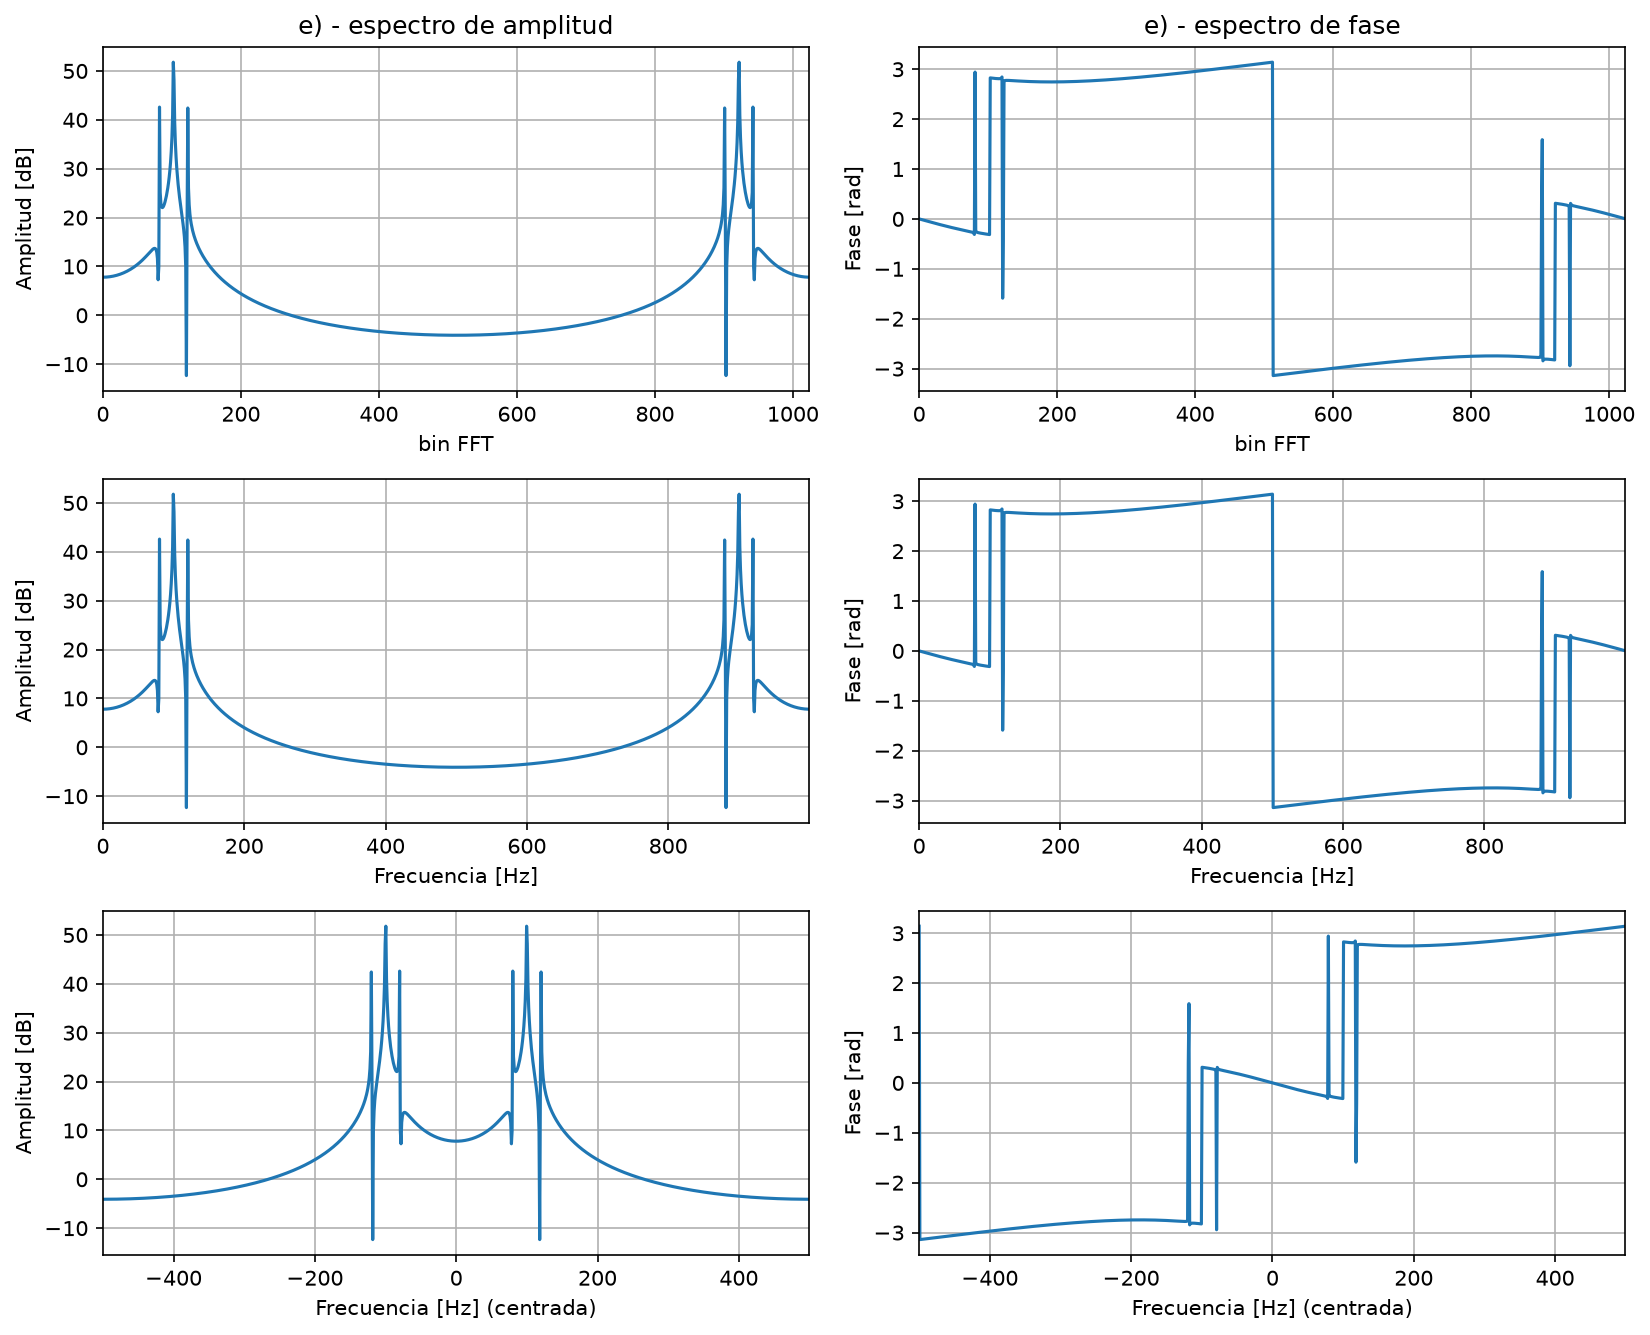

In [8]:
x_e = (1 + 0.5 * sin(2 * pi * 20 * t)) * sin(2 * pi * 100 * t)

plot_spectrum(x_e, sampling_freq_hz, "e)")